In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [31]:
# 1. Carregar os 4 ficheiros CSV fornecidos
wind_df = pd.read_csv('wind_288_per_MW.csv')
solar_df = pd.read_csv('solar_288h_representative_matrix.csv')
hydro_df = pd.read_csv('hydro_288h.csv')
load_df = pd.read_csv('Universal_Load_288.csv')

# 2. Parâmetros específicos da ilha de La Palma (Grupo 15)
P_BASE = 4.0   # MW (Tabela 4)
P_PEAK = 11.5  # MW (Tabela 4)
DAYS_IN_MONTH = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# 3. Transformação matemática da procura (Equação 1 do enunciado)
# P_demand(m,h) = P_base + M_0-1(m,h) * (P_peak - P_base)
load_df['P_demand_MW'] = P_BASE + load_df['Dimensionless_Load'] * (P_PEAK - P_BASE)

wind_dist = wind_df['Wind_pu']
solar_dist = solar_df['P_AC_per_MWp']
hydro_dist = hydro_df['Power (W)']


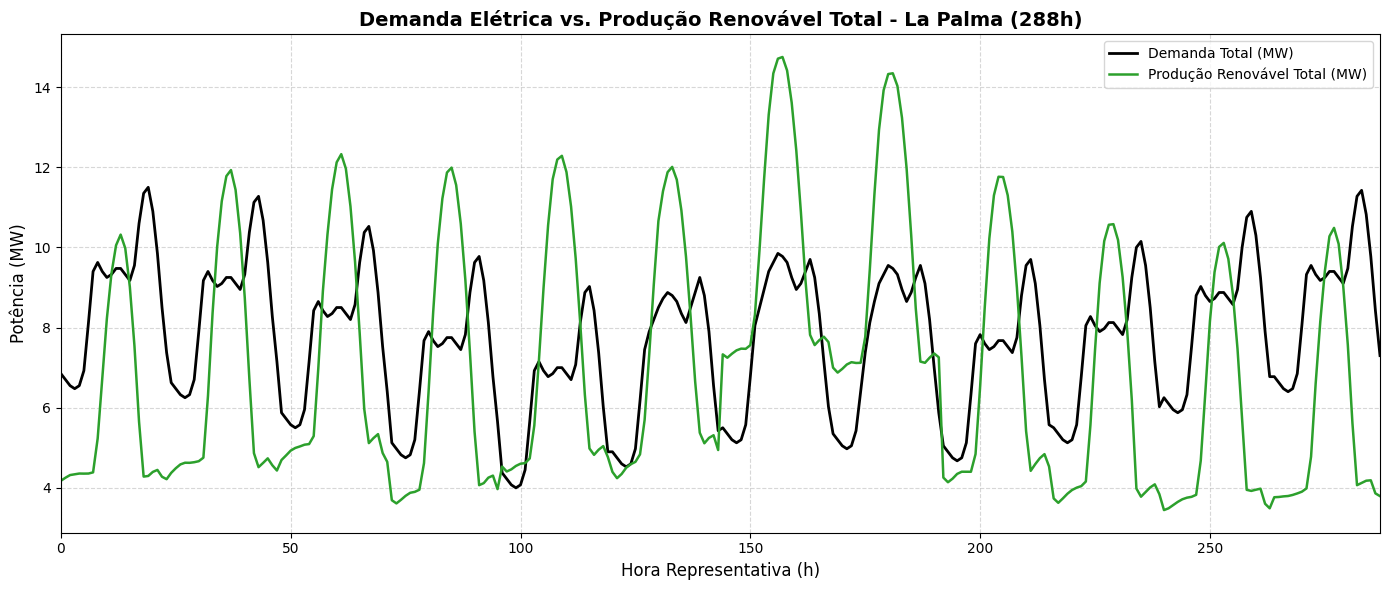

In [32]:
solar_power = 10
wind_power = 9.2
hydro_power = 0.84
renewables = solar_power * solar_dist + wind_power * wind_dist + hydro_dist / 1e6
demand = load_df['P_demand_MW']

plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda Total (MW)', color='black', linewidth=2)
plt.plot(renewables, label='Produção Renovável Total (MW)', color='tab:green', linewidth=1.8)

plt.title('Demanda Elétrica vs. Produção Renovável Total - La Palma (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()



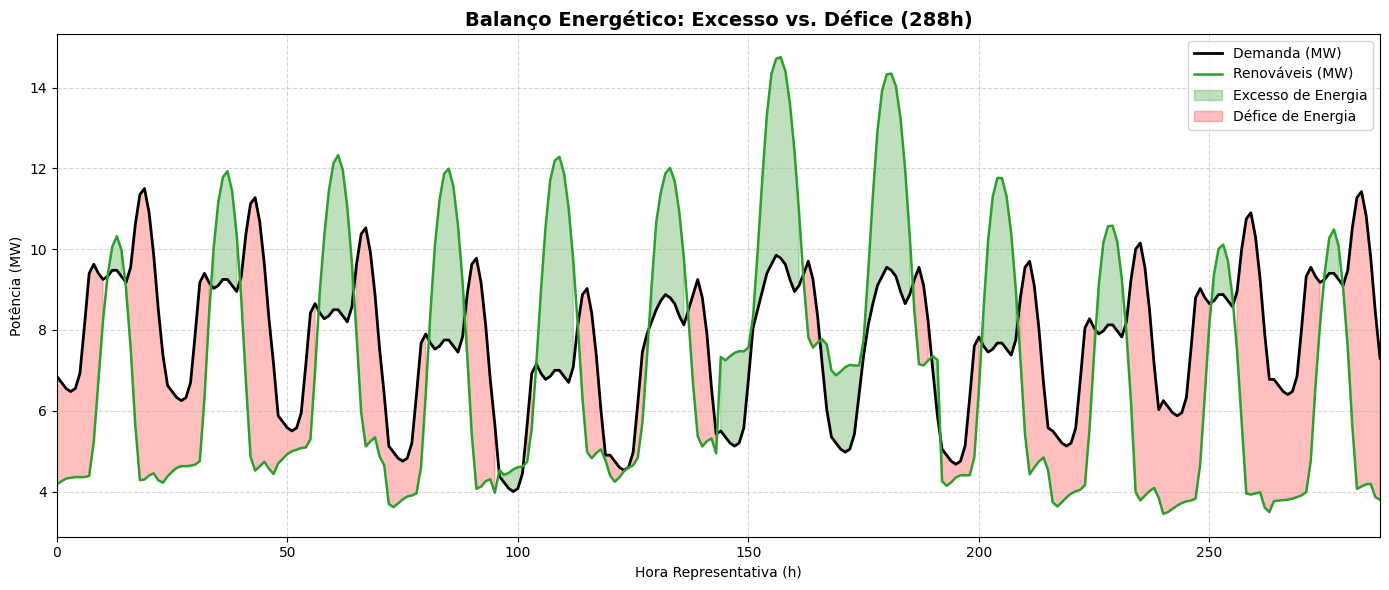

In [33]:
plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda (MW)', color='black', linewidth=2)
plt.plot(renewables, label='Renováveis (MW)', color='tab:green', linewidth=1.8)

# Preencher áreas de excesso (Renováveis > Demanda)
plt.fill_between(range(288), demand, renewables, where=(renewables >= demand), 
                 color='green', alpha=0.25, label='Excesso de Energia')

# Preencher áreas de défice (Renováveis < Demanda)
plt.fill_between(range(288), demand, renewables, where=(renewables < demand), 
                 color='red', alpha=0.25, label='Défice de Energia')

plt.title('Balanço Energético: Excesso vs. Défice (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)')
plt.ylabel('Potência (MW)')
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right')

plt.tight_layout()
plt.show()

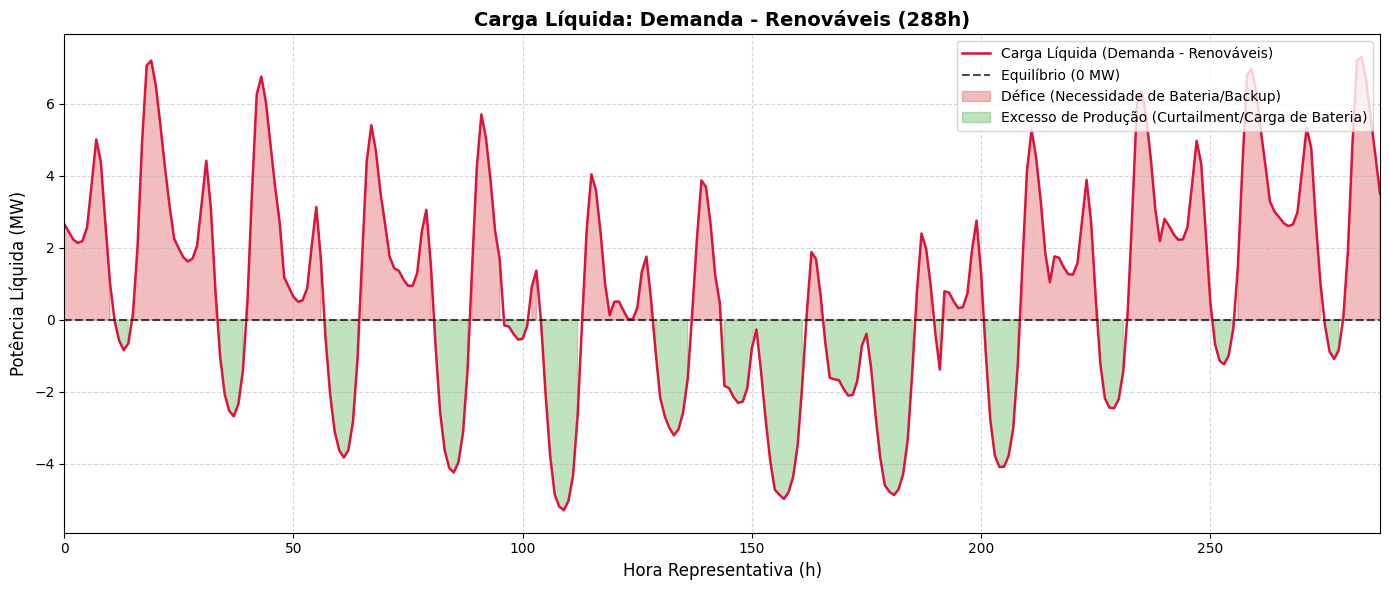

In [34]:
# Cálculo da Carga Líquida
net_load = demand - renewables

plt.figure(figsize=(14, 6))

# Linha da Carga Líquida
plt.plot(net_load, color='crimson', linewidth=1.8, label='Carga Líquida (Demanda - Renováveis)')

# Linha de referência (0 MW)
plt.axhline(0, color='black', linestyle='--', alpha=0.7, label='Equilíbrio (0 MW)')

# Preenchimento visual
plt.fill_between(range(288), net_load, 0, where=(net_load > 0), color='tab:red', alpha=0.3, label='Défice (Necessidade de Bateria/Backup)')
plt.fill_between(range(288), net_load, 0, where=(net_load < 0), color='tab:green', alpha=0.3, label='Excesso de Produção (Curtailment/Carga de Bateria)')

plt.title('Carga Líquida: Demanda - Renováveis (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência Líquida (MW)', fontsize=12)
plt.xlim(0, 287)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [35]:
# 1. Cálculo do perfil de potência térmica (MW) hora a hora
P_thermal = np.maximum(0, demand - renewables)

# 2. Principais parâmetros de dimensionamento
P_thermal_max = P_thermal.max()
print(f"Potência Térmica Máxima Necessária: {P_thermal_max:.2f} MW")

Potência Térmica Máxima Necessária: 7.30 MW


In [36]:
import pandas as pd
import numpy as np

DAYS_IN_MONTH = [31, 28, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31]

# Criar um array com 288 elementos contendo os dias correspondentes a cada hora
days_per_hour = np.repeat(DAYS_IN_MONTH, 24)


# 1. Défice puro de potência (Demanda - Renováveis)
net_load = demand - renewables
P_thermal_raw = np.maximum(0, net_load)

# 2. Capacidade Nominal e Carga Mínima Técnica (30%)
P_CAP = P_thermal_raw.max()      
P_MIN = 0.30 * P_CAP              


# Cenário B: Must-run (nunca baixa de P_MIN)
P_thermal_B = np.maximum(P_MIN, P_thermal_raw)

# 4. Cálculo da Energia Gerada nas 288h (MWh)
E_thermal_B = P_thermal_B.sum()

# 1. Energia Anual (MWh)
E_demand_annual = (demand * days_per_hour).sum()
E_renewables_annual = (renewables * days_per_hour).sum()


# Cenário B (Must-run contínuo a 30%)
E_thermal_B_annual = (P_thermal_B * days_per_hour).sum()

print(f"Demanda Total Anual: {E_demand_annual:,.2f} MWh")
print(f"Produção Renovável Total Anual: {E_renewables_annual:,.2f} MWh")
print(f"Energia Térmica Anual (Cenário B): {E_thermal_B_annual:,.2f} MWh")

Demanda Total Anual: 67,976.55 MWh
Produção Renovável Total Anual: 61,410.07 MWh
Energia Térmica Anual (Cenário B): 24,590.73 MWh


In [37]:
#Energia Renovável Anual por Fonte (MWh)
E_solar_annual = (solar_power * solar_dist * days_per_hour).sum()
E_wind_annual = (wind_power * wind_dist * days_per_hour).sum()
E_hydro_annual = (hydro_dist/1e6 * days_per_hour).sum()
E_renewables_annual = (renewables * days_per_hour).sum()

# 3. Demanda Total Anual (MWh)
E_demand_annual = (demand * days_per_hour).sum()

# 4. Energia Térmica Anual (MWh)
E_thermal_B_annual = (P_thermal_B * days_per_hour).sum()

# Impressão dos Resultados
print(f"Demanda Total Anual: {E_demand_annual:,.2f} MWh")
print(f"--- PRODUÇÃO RENOVÁVEL ---")
print(f"Produção Solar Anual: {E_solar_annual:,.2f} MWh")
print(f"Produção Eólica Anual: {E_wind_annual:,.2f} MWh")
print(f"Produção Hídrica Anual: {E_hydro_annual:,.2f} MWh")
print(f"Produção Renovável Total Anual: {E_renewables_annual:,.2f} MWh")
print(f"--- PRODUÇÃO TÉRMICA ---")
print(f"Energia Térmica Anual: {E_thermal_B_annual:,.2f} MWh")

Demanda Total Anual: 67,976.55 MWh
--- PRODUÇÃO RENOVÁVEL ---
Produção Solar Anual: 20,305.98 MWh
Produção Eólica Anual: 36,526.53 MWh
Produção Hídrica Anual: 4,577.55 MWh
Produção Renovável Total Anual: 61,410.07 MWh
--- PRODUÇÃO TÉRMICA ---
Energia Térmica Anual: 24,590.73 MWh


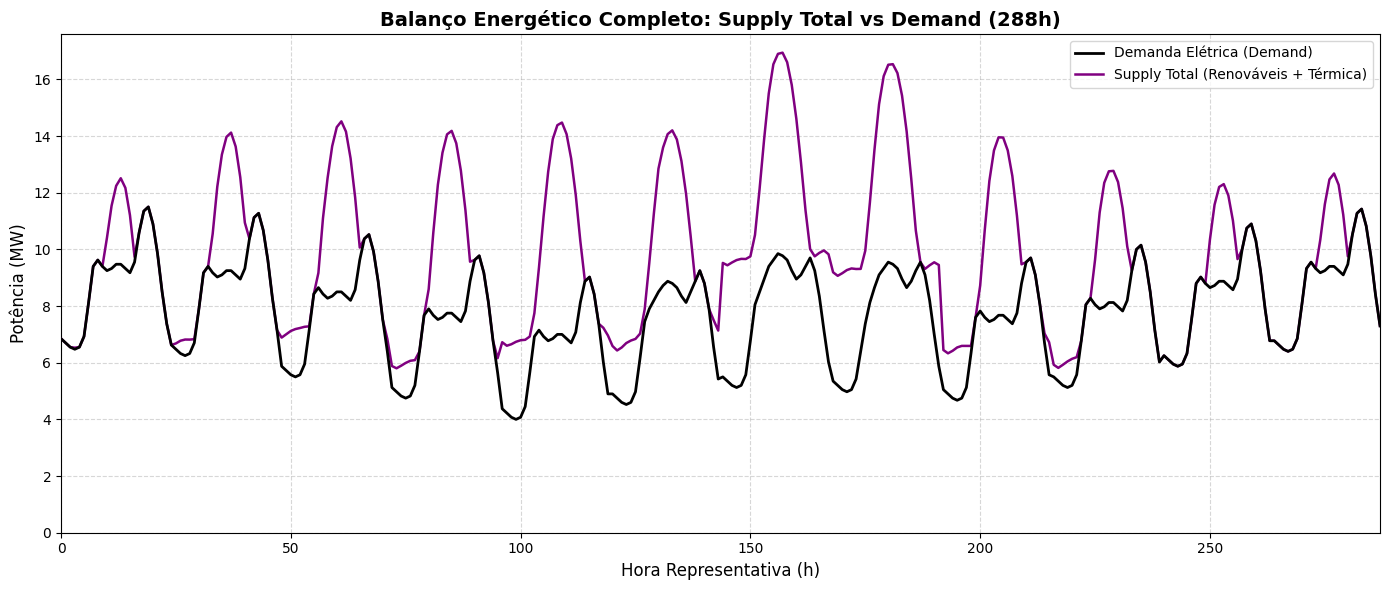

In [39]:

# 3. Supply Total (Renováveis + Não Renováveis)
total_supply = renewables + P_thermal_B

# 4. Gráfico
plt.figure(figsize=(14, 6))

plt.plot(demand, label='Demanda Elétrica (Demand)', color='black', linewidth=2, zorder=4)
plt.plot(total_supply, label='Supply Total (Renováveis + Térmica)', color='purple', linewidth=1.8, zorder=3)

plt.title('Balanço Energético Completo: Supply Total vs Demand (288h)', fontsize=14, fontweight='bold')
plt.xlabel('Hora Representativa (h)', fontsize=12)
plt.ylabel('Potência (MW)', fontsize=12)
plt.xlim(0, 287)
plt.ylim(bottom=0)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper right', frameon=True)

plt.tight_layout()
plt.show()

In [40]:

# 5. CÁLCULO DAS MÉTRICAS DA TABELA
Total_VRE_MW = solar_power + wind_power + hydro_power    
Total_Installed_MW = Total_VRE_MW + P_CAP           

# 1. VRE Energy Penetration (% AEP)
vre_energy_pen_net = ((E_demand_annual - E_thermal_B_annual) / E_demand_annual) * 100

# 2. VRE Capacity Penetration (% MW)
vre_capacity_pen = (Total_VRE_MW / Total_Installed_MW) * 100

# 3. VRE Overbuild Ratio (%)
vre_overbuild_ratio = (Total_VRE_MW / P_PEAK) * 100

# 6. Apresentação dos Resultados

print("     RESULTADOS DAS MÉTRICAS VRE")

print(f"VRE Energy Penetration (% AEP):           {vre_energy_pen_net:.1f}%")
print(f"VRE Capacity Penetration (% MW):          {vre_capacity_pen:.1f}%")
print(f"VRE Overbuild Ratio:                      {vre_overbuild_ratio:.0f}%")


     RESULTADOS DAS MÉTRICAS VRE
VRE Energy Penetration (% AEP):           63.8%
VRE Capacity Penetration (% MW):          73.3%
VRE Overbuild Ratio:                      174%


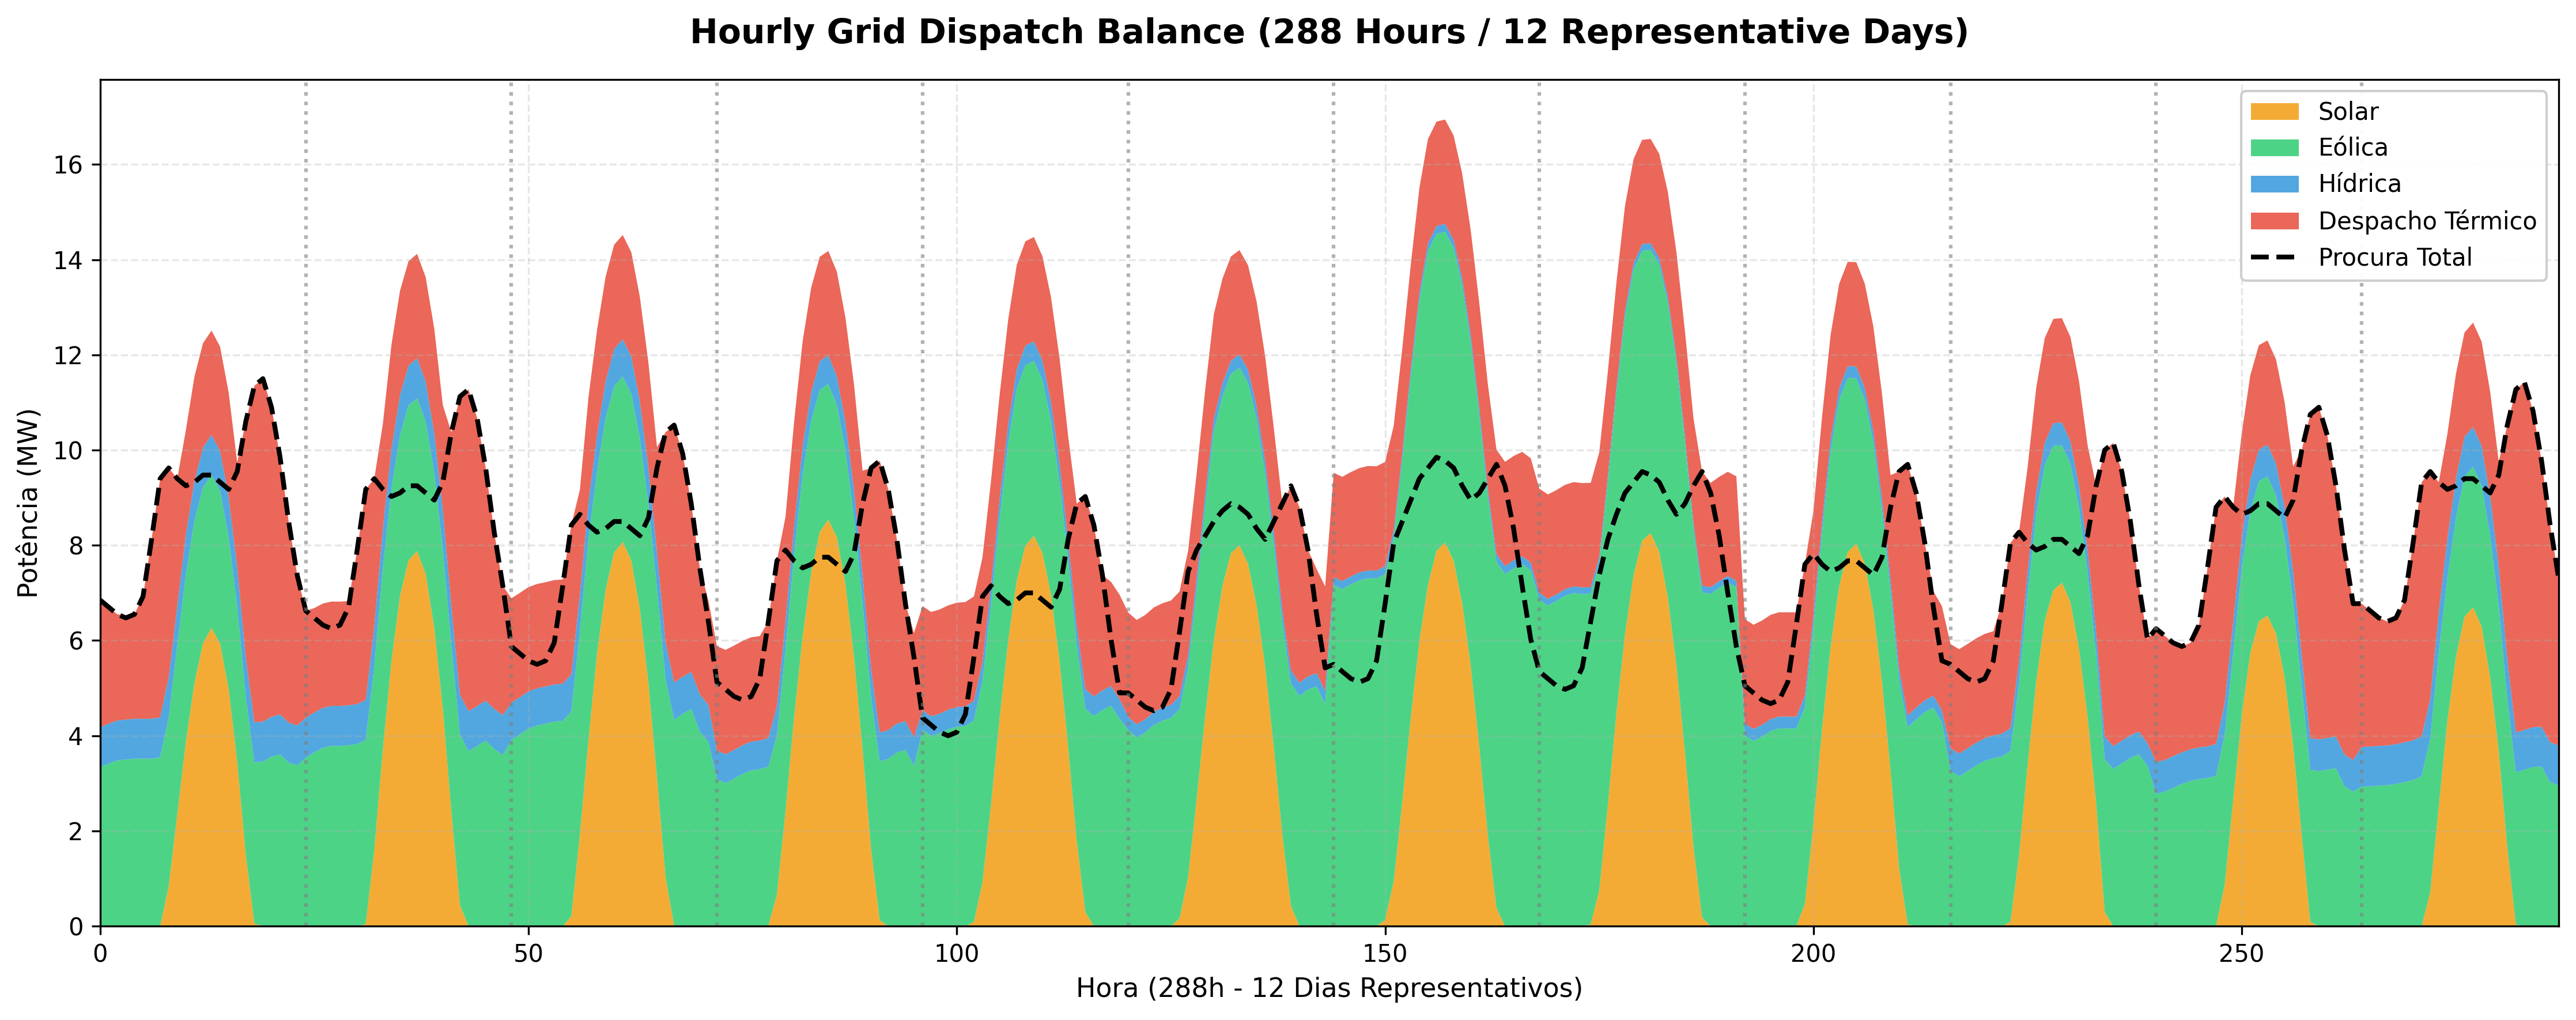

In [41]:
hours = np.arange(288)
plt.figure(figsize=(15, 6), dpi=300)

# Gráfico de área empilhada (Stacked Area Chart)
plt.stackplot(hours, solar_power * solar_dist, wind_power * wind_dist, hydro_dist/1e6, P_thermal_B, 
              labels=['Solar', 'Eólica', 'Hídrica', 'Despacho Térmico'],
              colors=['#f39c12', '#2ecc71', '#3498db', '#e74c3c'], alpha=0.85)

# Linha da procura total sobreposta
plt.plot(hours, demand, color='black', linewidth=2, linestyle='--', label='Procura Total')

# Separadores verticais a cada 24h (para separar os 12 meses representativos)
for m in range(1, 12):
    plt.axvline(x=m * 24, color='gray', linestyle=':', alpha=0.6)

# Estilização
plt.title('Hourly Grid Dispatch Balance (288 Hours / 12 Representative Days)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Hora (288h - 12 Dias Representativos)', fontsize=11)
plt.ylabel('Potência (MW)', fontsize=11)
plt.xlim(0, 287)
plt.legend(loc='upper right', frameon=True, facecolor='white', framealpha=0.95)
plt.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [45]:
# 1. Definir produções e procura em MW com as variáveis existentes
solar_gen = solar_power * solar_dist
wind_gen = wind_power * wind_dist
hydro_gen = hydro_dist / 1e6 if hydro_dist.max() > 1e3 else hydro_dist
demand = load_df['P_demand_MW'].values

# 2. Criar DataFrame com a estrutura de 288 horas (12 meses x 24h)
df_table = pd.DataFrame({
    'Month': np.repeat(range(1, 13), 24),
    'Hour': np.tile(range(24), 12),
    'Demand_MW': demand,
    'Wind_MW': wind_gen,
    'Solar_MW': solar_gen,
    'Hydro_MW': hydro_gen,
    'Thermal_MW' : P_thermal_B
})

# 3. Cálculo das dinâmicas do sistema
df_table['VRE_Total_MW'] = df_table['Wind_MW'] + df_table['Solar_MW'] + df_table['Hydro_MW']
df_table['Net_Load_MW'] = df_table['Demand_MW'] - df_table['VRE_Total_MW']

# Térmica e Excesso (Curtailment)
df_table['Curtailment_MW'] = np.maximum(0, df_table['VRE_Total_MW'] + df_table['Thermal_MW'] - df_table['Demand_MW'])

# Rampa térmica ascendente hora a hora: Thermal(t) - Thermal(t-1)
df_table['Thermal_Ramp_MW_h'] = df_table.groupby('Month')['Thermal_MW'].diff().fillna(0)

# 4. Agregação por Mês
table_12_df = pd.DataFrame()

table_12_df['Demand Value MW'] = df_table.groupby('Month')['Demand_MW'].mean()
table_12_df['Wind Value MW'] = df_table.groupby('Month')['Wind_MW'].mean()
table_12_df['Solar Value MW'] = df_table.groupby('Month')['Solar_MW'].mean()
table_12_df['Hydro Value MW'] = df_table.groupby('Month')['Hydro_MW'].mean()
table_12_df['Thermal Value MW'] = df_table.groupby('Month')['Thermal_MW'].mean()
table_12_df['Curtailment Value MW'] = df_table.groupby('Month')['Curtailment_MW'].mean()
table_12_df['Max Upward Thermal Ramp (MW/h)'] = df_table.groupby('Month')['Thermal_Ramp_MW_h'].max()
table_12_df['Minimum Net Load MW'] = df_table.groupby('Month')['Net_Load_MW'].min()

# Transpor para alinhar os meses nas colunas (1 a 12)
table_12_final = table_12_df.T
table_12_final.columns = [f'{m}' for m in range(1, 13)]

# Apresentar a tabela formatada com 1 casa decimal
display(table_12_final.round(1))

,1,2,3,4,5,6,7,8,9,10,11,12
Demand Value MW,8.8,8.6,7.9,7.1,6.4,7.2,7.9,7.7,7.0,7.5,8.2,8.8
Wind Value MW,3.4,3.6,4.0,3.2,4.1,4.3,7.1,6.7,4.0,3.3,3.0,3.1
Solar Value MW,1.7,2.3,2.4,2.7,2.6,2.6,2.6,2.6,2.5,2.1,1.8,1.8
Hydro Value MW,0.8,0.8,0.8,0.6,0.4,0.3,0.2,0.1,0.2,0.5,0.7,0.8
Thermal Value MW,3.5,3.1,2.6,2.7,2.4,2.3,2.2,2.2,2.6,3.0,3.5,3.7
Curtailment Value MW,0.6,1.2,2.0,2.0,3.1,2.3,4.2,4.0,2.3,1.4,0.7,0.6
Max Upward Thermal Ramp (MW/h),2.8,2.6,2.2,2.0,1.5,1.6,0.0,0.2,1.9,3.0,2.5,2.7
Minimum Net Load MW,-0.8,-2.7,-3.8,-4.2,-5.3,-3.2,-5.0,-4.9,-4.1,-2.5,-1.2,-1.1
